# MNIST bonus — a single JAX classifier versus a deep ensemble
This self-contained extension implements the **deep ensemble** option from Part II. The referenced `classification_mnist_pytorch.py` starter was not supplied in the workspace. PyTorch/torchvision is used only to load MNIST; the network, gradients and optimization use JAX.

**Run on Kaggle:** enable Internet for the initial MNIST download, choose a GPU if available, and Run All in a fresh session. The device printout below confirms whether JAX actually sees a GPU. Do not reinstall JAX if the existing runtime works. No local training has been performed for this notebook.

We train three independently initialized MLPs with separately shuffled mini-batches. The first member is the single-model baseline, so it receives exactly the same training budget as each ensemble member. The ensemble uses three times as many parameters and training updates overall. Hyperparameters are fixed in advance; a held-out validation split is monitored during training, and the official test split is evaluated only after all models are trained.

References: [torchvision MNIST loader](https://docs.pytorch.org/vision/main/generated/torchvision.datasets.MNIST.html), [JAX optimizers used in the practical](https://docs.jax.dev/en/latest/jax.example_libraries.optimizers.html).

In [1]:
import os
# Leave memory available to the notebook and other libraries on a GPU runtime.
os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false")
import json
import time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp
from jax import random, jit, value_and_grad
from jax.example_libraries import optimizers
from torchvision.datasets import MNIST
from IPython.display import display, Markdown

print("JAX:", jax.__version__, "Devices:", jax.devices())
if all(device.platform == "cpu" for device in jax.devices()):
    print("JAX is using CPU. Training will still work; selecting a GPU does not by itself ensure JAX sees it.")


JAX: 0.7.2 Devices: [CudaDevice(id=0), CudaDevice(id=1)]


## Configuration
Defaults: 3 members, 10 epochs per member, two hidden layers of width 150, batch size 256. If you need a shorter experiment, choose fewer epochs **before** running the experiment and report that budget. Choose settings using validation performance, never the test results.

In [2]:
M = 3
EPOCHS = 10
BATCH_SIZE = 256
LEARNING_RATE = 1e-3
VALIDATION_SIZE = 5000
SEED = 123
LAYER_SIZES = [784, 150, 150, 10]
OUTPUT_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path.cwd()
DATA_DIR = OUTPUT_DIR / "mnist_data"
assert M >= 2 and EPOCHS >= 1 and BATCH_SIZE >= 1


In [3]:
# Download only the official training split at this stage.
training_dataset = MNIST(root=str(DATA_DIR), train=True, download=True)
all_x = training_dataset.data.numpy().astype(np.float32).reshape(-1, 784) / 255.0
all_y = training_dataset.targets.numpy().astype(np.int32)
assert 0 < VALIDATION_SIZE < len(all_y)
indices = np.random.default_rng(SEED).permutation(len(all_y))
validation_indices, training_indices = indices[:VALIDATION_SIZE], indices[VALIDATION_SIZE:]
X_train, y_train = all_x[training_indices], all_y[training_indices]
X_val, y_val = all_x[validation_indices], all_y[validation_indices]
del all_x, all_y, training_dataset
print("Training:", X_train.shape, "Validation:", X_val.shape)


100%|██████████| 9.91M/9.91M [00:00<00:00, 17.0MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 468kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.19MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.58MB/s]


Training: (55000, 784) Validation: (5000, 784)


## Network and training objective
Each flattened $28\times28$ image has 784 inputs. The network produces 10 logits. We minimize mean categorical NLL:
$$\mathcal L(\theta)=-\frac1B\sum_{i=1}^B\log p_\theta(y_i\mid x_i).$$
This bonus uses the unregularized categorical NLL and Adam, without adversarial training. Stable log-softmax avoids taking logarithms of rounded-to-zero probabilities.

In [4]:
def init_params(key):
    keys = random.split(key, len(LAYER_SIZES) - 1)
    return [(random.normal(k, (din, dout)) * np.sqrt(2.0 / din),
             jnp.zeros(dout))
            for k, din, dout in zip(keys, LAYER_SIZES[:-1], LAYER_SIZES[1:])]

@jit
def predict_log_probs(params, x):
    for weights, bias in params[:-1]:
        x = jax.nn.relu(x @ weights + bias)
    weights, bias = params[-1]
    return jax.nn.log_softmax(x @ weights + bias, axis=-1)

def nll_loss(params, x, y):
    log_probs = predict_log_probs(params, x)
    return -jnp.mean(log_probs[jnp.arange(y.shape[0]), y])

opt_init, opt_update, get_params = optimizers.adam(LEARNING_RATE)

@jit
def train_step(step, state, x, y):
    value, gradients = value_and_grad(nll_loss)(get_params(state), x, y)
    return opt_update(step, gradients, state), value

def predict_in_batches(params, x):
    # Copies each completed batch to CPU and synchronizes device execution.
    return np.concatenate([
        np.asarray(predict_log_probs(params, jnp.asarray(x[start:start+BATCH_SIZE])))
        for start in range(0, len(x), BATCH_SIZE)
    ])

def metrics(log_probs, labels):
    assert log_probs.shape == (len(labels), 10)
    assert np.isfinite(log_probs).all()
    np.testing.assert_allclose(np.exp(log_probs).sum(axis=-1), 1.0, atol=2e-5)
    return {"accuracy": float(np.mean(log_probs.argmax(axis=-1) == labels)),
            "NLL": float(-np.mean(log_probs[np.arange(len(labels)), labels]))}


In [5]:
models, histories, training_seconds = [], [], []
model_keys = random.split(random.PRNGKey(SEED), M)
for member, key in enumerate(model_keys):
    params = init_params(key)
    state = opt_init(params)
    shuffle_rng = np.random.default_rng(SEED + 1000 + member)
    history = []
    step = 0
    started = time.perf_counter()
    for epoch in range(EPOCHS):
        order = shuffle_rng.permutation(len(y_train))
        accumulated_nll = 0.0
        for start in range(0, len(order), BATCH_SIZE):
            ids = order[start:start+BATCH_SIZE]
            state, batch_loss = train_step(step, state, jnp.asarray(X_train[ids]),
                                          jnp.asarray(y_train[ids]))
            accumulated_nll += float(batch_loss) * len(ids)
            step += 1
        params = get_params(state)
        validation = metrics(predict_in_batches(params, X_val), y_val)
        row = {"epoch": epoch + 1, "train_NLL": accumulated_nll / len(y_train),
               "validation_accuracy": validation["accuracy"], "validation_NLL": validation["NLL"]}
        assert np.isfinite(list(row.values())).all(), "Training became non-finite."
        history.append(row)
        print(f"Member {member+1}/{M}, epoch {epoch+1}/{EPOCHS}: "
              f"train NLL={row['train_NLL']:.4f}, "
              f"validation accuracy={validation['accuracy']:.4f}, NLL={validation['NLL']:.4f}")
    # Keep the final epoch for every member; no selection using test labels.
    models.append(jax.device_get(params))
    histories.append(history)
    training_seconds.append(time.perf_counter() - started)
print("All members trained. Test data has not been evaluated during training.")


Member 1/3, epoch 1/10: train NLL=0.3746, validation accuracy=0.9392, NLL=0.2032
Member 1/3, epoch 2/10: train NLL=0.1455, validation accuracy=0.9596, NLL=0.1408
Member 1/3, epoch 3/10: train NLL=0.0979, validation accuracy=0.9626, NLL=0.1230
Member 1/3, epoch 4/10: train NLL=0.0748, validation accuracy=0.9652, NLL=0.1137
Member 1/3, epoch 5/10: train NLL=0.0578, validation accuracy=0.9678, NLL=0.0977
Member 1/3, epoch 6/10: train NLL=0.0456, validation accuracy=0.9720, NLL=0.0982
Member 1/3, epoch 7/10: train NLL=0.0354, validation accuracy=0.9710, NLL=0.1057
Member 1/3, epoch 8/10: train NLL=0.0292, validation accuracy=0.9678, NLL=0.0987
Member 1/3, epoch 9/10: train NLL=0.0218, validation accuracy=0.9738, NLL=0.0947
Member 1/3, epoch 10/10: train NLL=0.0180, validation accuracy=0.9734, NLL=0.1052
Member 2/3, epoch 1/10: train NLL=0.3778, validation accuracy=0.9382, NLL=0.2035
Member 2/3, epoch 2/10: train NLL=0.1462, validation accuracy=0.9542, NLL=0.1532
Member 2/3, epoch 3/10: tra

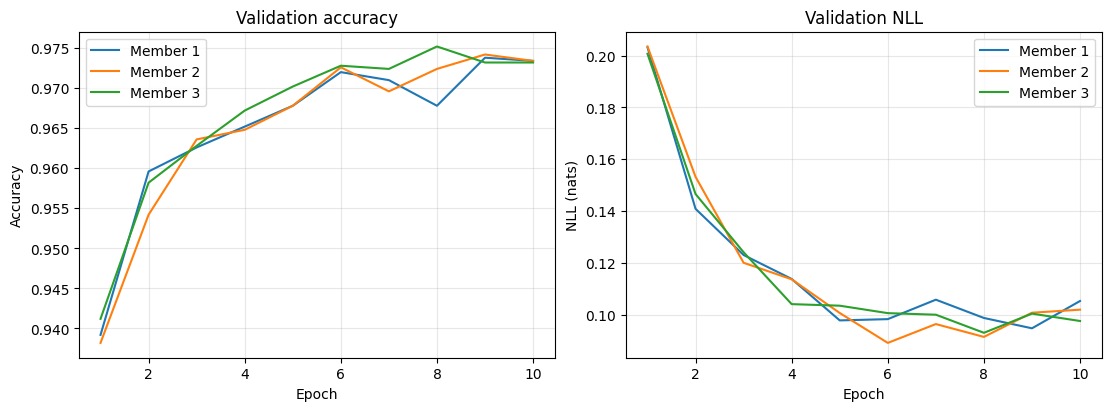

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for member, history in enumerate(histories):
    epochs = [row["epoch"] for row in history]
    axes[0].plot(epochs, [row["validation_accuracy"] for row in history], label=f"Member {member+1}")
    axes[1].plot(epochs, [row["validation_NLL"] for row in history], label=f"Member {member+1}")
axes[0].set(title="Validation accuracy", xlabel="Epoch", ylabel="Accuracy")
axes[1].set(title="Validation NLL", xlabel="Epoch", ylabel="NLL (nats)")
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend()
plt.show()


## Evaluate the single model and ensemble
For an equally weighted ensemble,
$$p_{\rm ens}(y\mid x)=\frac1M\sum_{m=1}^M p_m(y\mid x).$$
We compute its log probabilities using log-sum-exp, which is mathematically the log of averaged probabilities. Averaging member NLLs would evaluate a different quantity; averaging logits would define a different ensemble. The test set is not used to choose members or training settings.

In [7]:
test_dataset = MNIST(root=str(DATA_DIR), train=False, download=True)
X_test = test_dataset.data.numpy().astype(np.float32).reshape(-1, 784) / 255.0
y_test = test_dataset.targets.numpy().astype(np.int32)
member_log_probs = np.stack([predict_in_batches(model, X_test) for model in models])
ensemble_log_probs = np.logaddexp.reduce(member_log_probs.astype(np.float64), axis=0) - np.log(M)
single_metrics = metrics(member_log_probs[0], y_test)
ensemble_metrics = metrics(ensemble_log_probs, y_test)
parameter_count = sum(p.size for p in jax.tree_util.tree_leaves(models[0]))
updates_per_member = EPOCHS * int(np.ceil(len(y_train) / BATCH_SIZE))

# Entropy decomposition on the official test set; these are model-based proxies.
probabilities = np.exp(member_log_probs.astype(np.float64))
ensemble_probabilities = np.exp(ensemble_log_probs)
total_entropy = -np.sum(ensemble_probabilities * ensemble_log_probs, axis=-1)
average_member_entropy = -np.sum(probabilities * member_log_probs, axis=-1).mean(axis=0)
disagreement = np.maximum(total_entropy - average_member_entropy, 0.0)

results = {
    "single_model": single_metrics, "deep_ensemble": ensemble_metrics,
    "members": M, "epochs_per_member": EPOCHS, "updates_per_member": updates_per_member,
    "training_examples": len(y_train), "validation_examples": len(y_val), "test_examples": len(y_test),
    "parameters_single": int(parameter_count), "parameters_ensemble": int(M * parameter_count),
    "mean_test_entropy": float(total_entropy.mean()),
    "mean_test_member_entropy": float(average_member_entropy.mean()),
    "mean_test_disagreement": float(disagreement.mean()),
    "training_seconds_per_member_including_validation": training_seconds,
    "jax_version": jax.__version__, "devices": str(jax.devices()),
}
(OUTPUT_DIR / "mnist_bonus_results.json").write_text(json.dumps(results, indent=2))
print(json.dumps(results, indent=2))


{
  "single_model": {
    "accuracy": 0.9782,
    "NLL": 0.08110295236110687
  },
  "deep_ensemble": {
    "accuracy": 0.9823,
    "NLL": 0.05996601708970188
  },
  "members": 3,
  "epochs_per_member": 10,
  "updates_per_member": 2150,
  "training_examples": 55000,
  "validation_examples": 5000,
  "test_examples": 10000,
  "parameters_single": 141910,
  "parameters_ensemble": 425730,
  "mean_test_entropy": 0.0588924353351785,
  "mean_test_member_entropy": 0.04547958303134538,
  "mean_test_disagreement": 0.01341285230383312,
  "training_seconds_per_member_including_validation": [
    5.273856615,
    3.2086220520000097,
    3.1674289380000005
  ],
  "jax_version": "0.7.2",
  "devices": "[CudaDevice(id=0), CudaDevice(id=1)]"
}


In [8]:
accuracy_change = 100 * (ensemble_metrics["accuracy"] - single_metrics["accuracy"])
nll_change = ensemble_metrics["NLL"] - single_metrics["NLL"]
accuracy_outcome = "increased" if accuracy_change > 0 else "decreased" if accuracy_change < 0 else "was unchanged"
nll_outcome = "improved" if nll_change < 0 else "worsened" if nll_change > 0 else "was unchanged"
report = f"""## Results and discussion

| Model | Test accuracy | Test NLL | Parameters |
| --- | ---: | ---: | ---: |
| Single model (first member) | {single_metrics['accuracy']:.2%} | {single_metrics['NLL']:.5f} | {parameter_count:,} |
| Deep ensemble ({M} members) | {ensemble_metrics['accuracy']:.2%} | {ensemble_metrics['NLL']:.5f} | {M*parameter_count:,} |

With {EPOCHS} epochs and {updates_per_member:,} mini-batch updates per member, ensemble accuracy {accuracy_outcome} (change: {accuracy_change:+.3f} percentage points), while NLL {nll_outcome} (change: {nll_change:+.5f}; lower is better). These are results from this run, not a guarantee that ensembling always improves either metric.

Independent initialization and mini-batch order create different fitted models. Averaging their predictive distributions can reduce the effect of an individual model's errors. Accuracy depends only on the most probable class, whereas NLL depends on the probability assigned to the true label, so the metrics can change differently.

Mean test predictive entropy is {total_entropy.mean():.5f} nats. It decomposes into mean member entropy {average_member_entropy.mean():.5f} plus mean disagreement {disagreement.mean():.5f}. These are model-based uncertainty proxies; neither this decomposition nor test NLL alone establishes calibration or out-of-distribution reliability.

The ensemble needs {M} forward passes per input and {M} times the parameter storage. Each member received the same budget as the baseline, so this is not a matched-total-compute comparison. Reported training durations include validation and compilation and should not be treated as a controlled speed benchmark. No test labels were used for model selection.
"""
display(Markdown(report))
(OUTPUT_DIR / "mnist_bonus_discussion.md").write_text(report)
print("Saved results and discussion to", OUTPUT_DIR)


## Results and discussion

| Model | Test accuracy | Test NLL | Parameters |
| --- | ---: | ---: | ---: |
| Single model (first member) | 97.82% | 0.08110 | 141,910 |
| Deep ensemble (3 members) | 98.23% | 0.05997 | 425,730 |

With 10 epochs and 2,150 mini-batch updates per member, ensemble accuracy increased (change: +0.410 percentage points), while NLL improved (change: -0.02114; lower is better). These are results from this run, not a guarantee that ensembling always improves either metric.

Independent initialization and mini-batch order create different fitted models. Averaging their predictive distributions can reduce the effect of an individual model's errors. Accuracy depends only on the most probable class, whereas NLL depends on the probability assigned to the true label, so the metrics can change differently.

Mean test predictive entropy is 0.05889 nats. It decomposes into mean member entropy 0.04548 plus mean disagreement 0.01341. These are model-based uncertainty proxies; neither this decomposition nor test NLL alone establishes calibration or out-of-distribution reliability.

The ensemble needs 3 forward passes per input and 3 times the parameter storage. Each member received the same budget as the baseline, so this is not a matched-total-compute comparison. Reported training durations include validation and compilation and should not be treated as a controlled speed benchmark. No test labels were used for model selection.


Saved results and discussion to /kaggle/working


## Submission
Save the executed notebook with its outputs. The results cell also writes `mnist_bonus_results.json` and `mnist_bonus_discussion.md` into `/kaggle/working`. Read the generated discussion and check that it matches your run before including it with the practical. The saved Kaggle run completed all three members. Test accuracy increased from 97.82% to 98.23%, and test NLL decreased from 0.08110 to 0.05997. The extension has now been trained and evaluated.

## Reflection on LLM use and learning

### 1. Which LLM I used and how
I used OpenAI Codex, a GPT-6-based assistant, as a tutor, coding assistant and writing aid during this practical. My use went beyond formatting: it included explanations, implementation suggestions, generated code, debugging, and help drafting interpretations and this reflection.

For the mathematics, I asked the assistant to convert equations into LaTeX that I could paste into notebook Markdown cells. I also asked it to explain the intermediate steps in the Gaussian KL derivation: expanding the two log densities and taking expectations under $Q_\omega(\theta)$. In particular, the identities $\mathbb E_Q[(\theta_j-\mu_j)^2]=\sigma_j^2$ and $\mathbb E_Q[\theta_j^2]=\mu_j^2+\sigma_j^2$ explain where the terms in the closed-form KL come from. Here $Q_\omega$ is the **approximate posterior**, while $P(\theta)$ is the prior. This distinction helped me connect the mathematical objective to the implementation.

The assistant explained variable types, array shapes, and the supplied helper functions, allowing me to focus on how they fit into the TODO components. It helped implement the VI loss and reparameterized layer, completed ensemble/MIMO implementations and comparison code, and generated a self-contained JAX MNIST deep-ensemble extension because the referenced starter script was not available in my workspace. It also helped compare the saved results with the written discussions and corrected a variance-versus-standard-deviation error in my first written Gaussian derivation. I ran the notebooks on Kaggle and supplied the resulting files for review. Some earlier ensemble checks were run by the assistant locally; the final numerical discussions use the saved Kaggle results. The assistant helped draft this disclosure and prepare the PDF exports.

### 2. Benefits and limitations for my learning
The main benefit was reducing the time spent on unfamiliar JAX syntax, helper-function interfaces and equation formatting. Step-by-step explanations helped connect the probability distributions to executable operations: summing over observations, summing over parameter coordinates, applying softplus to standard deviations, and sampling with the reparameterization trick. This made it easier to concentrate on the purpose of each loss term and on the differences between aleatoric and epistemic uncertainty.

The main drawback is that receiving complete code can replace the practice of constructing and debugging an implementation myself. A notebook that runs is not evidence that I could reproduce every part unaided. Fluent explanations can also appear more reliable than they are. During this work, the written Gaussian derivation needed correction, and discussion values from an earlier run had to be replaced with the actual Kaggle outputs. These are reasons to check both the mathematics and the evidence rather than accept generated text automatically.

My assessment is that LLM support improved my access to the concepts and my ability to finish the experiments, but reduced the amount of independent implementation practice. To consolidate the learning, I should be able to derive the losses, explain the tensor shapes and trace the sampling and ensembling code without referring to the assistant. I regard generated code as something I must understand and defend, not as evidence of mastery on its own.

### 3. Should LLM use be allowed?
I support allowing LLMs in practical assignments with transparent disclosure and responsibility for the submitted work. They can help students overcome programming and notation barriers while exploring the intended concepts. However, unrestricted copying without understanding would weaken the learning objective and make assessment less informative.

A useful policy would distinguish tutoring, formatting, debugging and code generation, and require students to state which forms of help they used. Students should verify generated claims against their actual experiments and be prepared to explain a derivation or modify part of the implementation independently. Short oral questions or an unaided component could assess that understanding. This would preserve the educational benefits of LLM assistance while assessing what the student has learned, rather than only the quality of the final generated notebook.
